# The shots Oklahoma City allows

Joseph Smarrelli · September 2026 · Thunder opponent scouting

Oklahoma City’s opponents took a larger share of their field goal attempts from the corners and a smaller share at the rim than the league overall. The corner difference is a useful place to begin an offensive review. It does not establish that an open corner three is available on demand.

The second part of the study asks whether location and shooter history explain the scoring on those attempts. A model trained on the previous season still overpredicts opponent field-goal production against OKC by about **4.0 points per 100 attempts**. The larger negative gaps are inside the arc.



In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import display, Image
from src import shot_model
summary = shot_model.run()
from src import figures
figures.run()
summary

{'validation': {'training_attempts': 218905,
  'test_attempts': 215859,
  'test_games': 1212,
  'model_logloss': 0.6485987898495147,
  'baseline_logloss': 0.6570204590529689,
  'model_brier': 0.22865574963312413,
  'baseline_brier': 0.2322256589494198,
  'loss_difference': -0.008421669203454434,
  'lower': -0.00913161239535603,
  'upper': -0.0076531152094916,
  'training_season': '2024-25',
  'test_season': '2025-26'},
 'teams': [{'defense': 'OKC',
   'attempts': 7244,
   'games': 82,
   'actual': np.float64(1.0371341800110436),
   'expected': np.float64(1.0769694913763328),
   'residual': -0.039835311365289096,
   'lower': -0.06719883984308277,
   'upper': -0.01280592873119548,
   'corner_share': np.float64(0.13210933186085036),
   'rim_share': np.float64(0.2545554942020983)},
  {'defense': 'DEN',
   'attempts': 7292,
   'games': 80,
   'actual': np.float64(1.0850246845858476),
   'expected': np.float64(1.0762307855064153),
   'residual': 0.008793899079432286,
   'lower': -0.015370128

## Results
The following table is regenerated from the pinned inputs.

In [2]:
pd.read_csv('results/defense_zone_profiles.csv')

,defense,zone,attempts,share,actual,expected,residual,lower,upper
0,OKC,Above-break three,2229,0.307703,1.065949,1.064110,0.001839,-0.046301,0.048808
1,OKC,Corner three,957,0.132109,1.200627,1.145031,0.055596,-0.037932,0.145890
2,OKC,Midrange,774,0.106847,0.749354,0.835825,-0.086471,-0.151535,-0.017621
3,OKC,Other paint,1440,0.198785,0.804167,0.877680,-0.073513,-0.128373,-0.020383
4,OKC,Rim,1844,0.254555,1.220174,1.314037,-0.093864,-0.142169,-0.043171
5,DEN,Above-break three,2240,0.307186,1.029911,1.065410,-0.035499,-0.093025,0.018338
6,DEN,Corner three,885,0.121366,1.088136,1.152422,-0.064286,-0.154129,0.032740
7,DEN,Midrange,781,0.107104,0.819462,0.836557,-0.017095,-0.088083,0.049640
8,DEN,Other paint,1495,0.205019,0.908361,0.878601,0.029760,-0.018942,0.076880
9,DEN,Rim,1891,0.259325,1.398202,1.308622,0.089580,0.042815,0.138114


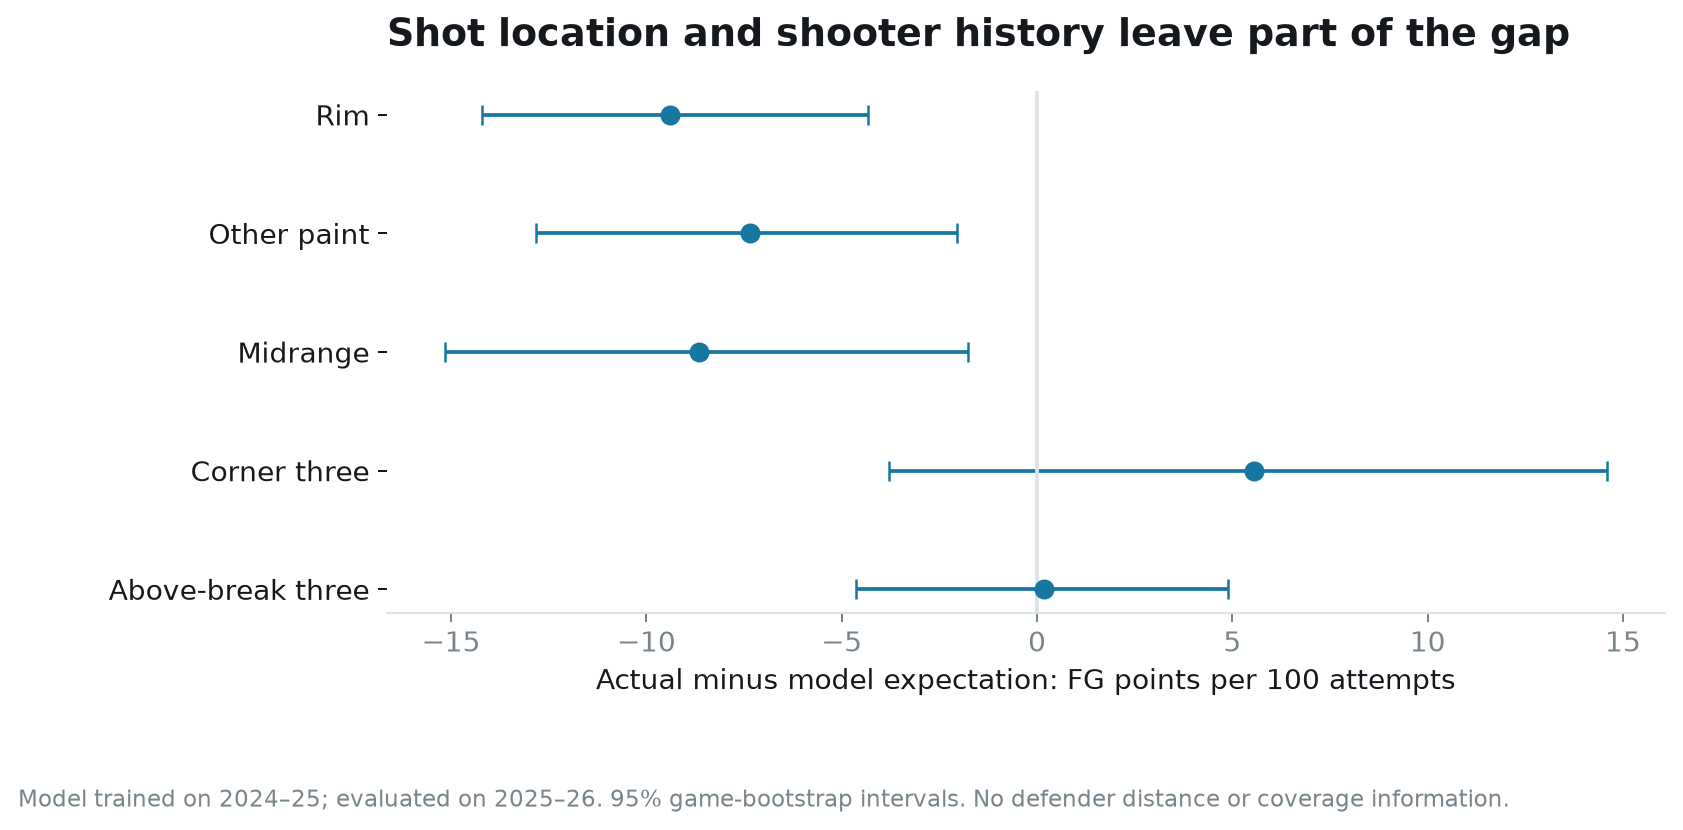

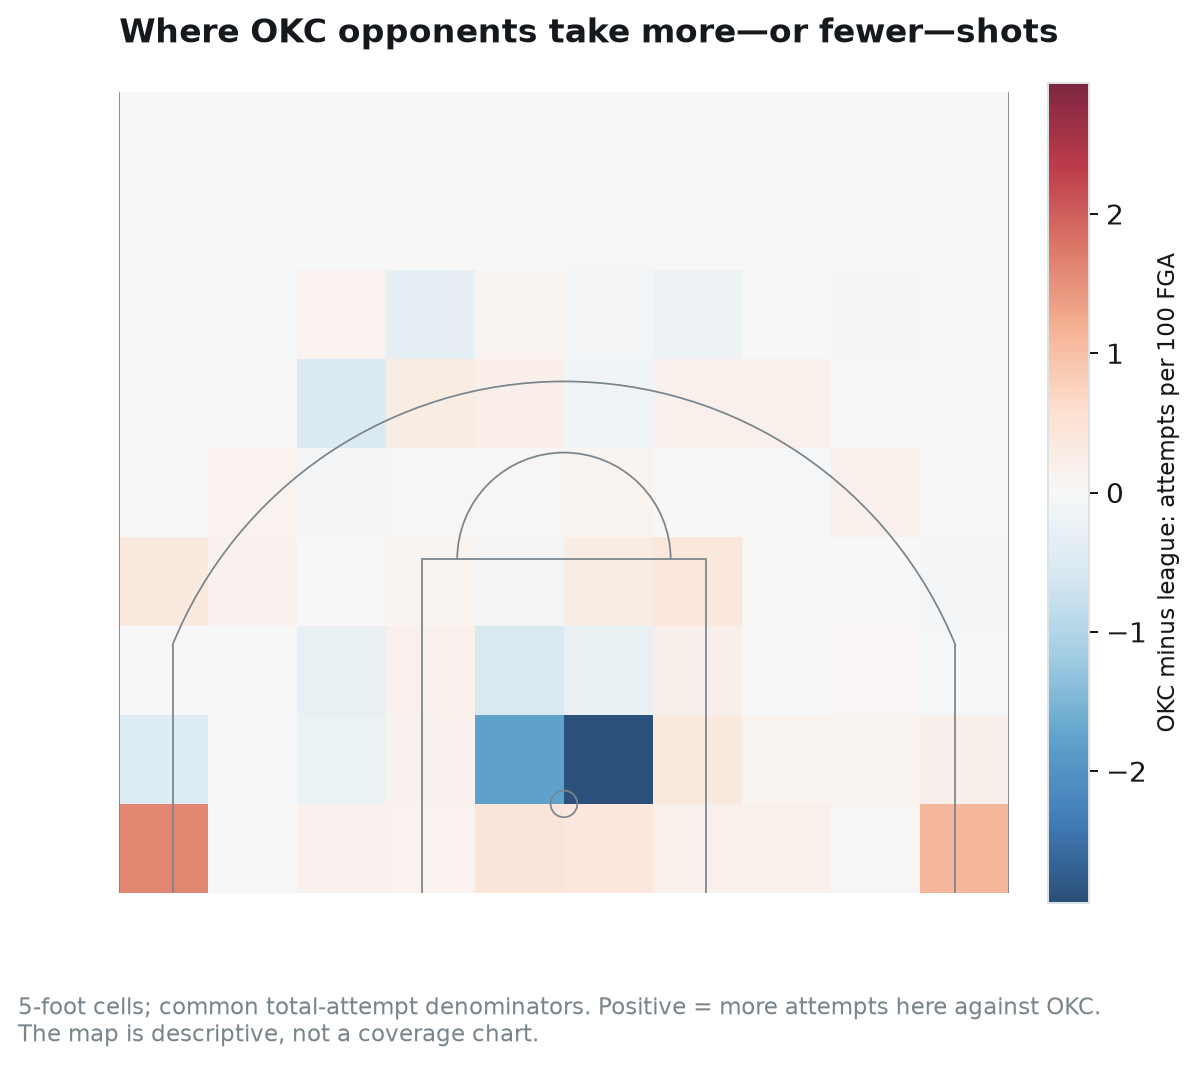

In [3]:
display(Image(filename='figures/okc_conversion.png'))
display(Image(filename='figures/okc_spatial.png'))

## Recalculate evaluation loss and inspect calibration
These predictions use the previous season for model training and shooter history. The current season provides held-out outcomes.

In [4]:
import json, numpy as np
from src.statistics import loss
d = pd.read_csv('data/shot_validation_rows.csv.gz')
v = json.loads(Path('results/shot_validation.json').read_text())
assert np.isclose(loss(d.made, d.probability).mean(), v['model_logloss'])
display(v)
display(pd.read_csv('results/shot_calibration.csv'))

{'training_attempts': 218905,
 'test_attempts': 215859,
 'test_games': 1212,
 'model_logloss': 0.6485987898495147,
 'baseline_logloss': 0.6570204590529689,
 'model_brier': 0.22865574963312413,
 'baseline_brier': 0.2322256589494198,
 'loss_difference': -0.008421669203454434,
 'lower': -0.00913161239535603,
 'upper': -0.0076531152094916,
 'training_season': '2024-25',
 'test_season': '2025-26'}

,prob_bin,attempts,predicted,observed
0,"(0.1, 0.2]",5,0.198069,0.200000
1,"(0.2, 0.3]",1601,0.278822,0.276702
2,"(0.3, 0.4]",86441,0.362029,0.359667
3,"(0.4, 0.5]",71003,0.436093,0.441010
4,"(0.5, 0.6]",15666,0.560560,0.573727
5,"(0.6, 0.7]",18281,0.642199,0.646573
6,"(0.7, 0.8]",13497,0.746367,0.753797
7,"(0.8, 0.9]",9303,0.836888,0.844029
8,"(0.9, 1.0]",62,0.906887,0.854839


## Interpretation and limits
Read the complete accompanying article for denominators, uncertainty, model selection, and the basketball decisions this analysis cannot identify. The results here are historical research, not a claim of team deployment.